# Notebook 06 — Personalized Purchase Clock

**Project:** Customer Segmentation and Retention Analysis Using Machine Learning and Statistical Modelling  
**Dataset:** UCI Online Retail II, Year 1 only  
**Purpose:** Compare one global baseline, a historical-segment baseline, and a personalized discrete-time hazard model for return within 30, 60, and 90 days.

This notebook creates historical forecasts at the 2010 cutoffs in the validated framework. These are **not real-time forecasts for 2026**. A purchase within a horizon is an observed return, not proof of permanent retention; no return within a horizon is not a permanent churn label.

## 1. Research objective

At a cutoff date, estimate the probability of a customer's next valid purchase occurring within 30, 60, or 90 days. We compare a pooled global curve, a curve conditioned on the historically assigned K-Means segment, and a pooled Logistic Regression hazard model using compact customer history features. All methods use the same outcome-matured 90-day TRAIN / VAL / TEST schedule.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the repository root whether the notebook is run from the root or notebooks/.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "src" / "temporal_framework.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate src/temporal_framework.py from the notebook working directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import purchase_clock as pc
from src import temporal_framework as tf

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "temporal"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "purchase_clock"
MODEL_DIR = PROJECT_ROOT / "models" / "purchase_clock"
FIGURE_DIR = OUTPUT_DIR / "figures"
for _directory in (OUTPUT_DIR, MODEL_DIR, FIGURE_DIR):
    _directory.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Model directory: {MODEL_DIR}")

Project root: /home/runner/workspace/OELP_project
Output directory: /home/runner/workspace/OELP_project/data/processed/purchase_clock
Model directory: /home/runner/workspace/OELP_project/models/purchase_clock


## 2. Data sources and temporal split verification

Only `predictive_splits_90d.csv` is used for this coherent purchase clock. The other predictive split files are not mixed into training. Descriptive-only combined cutoff tables are not used. For each role, customer features come from the validated split and actual outcomes are reconstructed with `temporal_framework.compute_future_targets` from the order-level file.

In [2]:
metadata_path = DATA_DIR / "temporal_split_metadata.json"
with metadata_path.open(encoding="utf-8") as handle:
    temporal_metadata = json.load(handle)

split_path = DATA_DIR / "predictive_splits_90d.csv"
model_features = [
    "Customer ID", "cutoff_date", "Hist_Cluster_id", "Hist_Segment",
    *pc.NUMERIC_FEATURES,
]
# Target columns are deliberately not loaded before validation selects C.
splits = pd.read_csv(
    split_path,
    usecols=[*model_features, "split_role", "horizon_days"],
    parse_dates=["cutoff_date"],
)
orders = pd.read_csv(DATA_DIR / "orders.csv", parse_dates=["PurchaseDate"])

expected_cutoffs = {
    "TRAIN": pd.Timestamp("2010-03-01"),
    "VAL": pd.Timestamp("2010-06-01"),
    "TEST": pd.Timestamp("2010-09-10"),
}
assert set(splits["split_role"].unique()) == set(expected_cutoffs)
assert (splits["horizon_days"] == 90).all()
assert orders["Customer ID"].isin([14103, 14827]).sum() == 0
assert (~orders["Invoice"].astype(str).str.startswith("C")).all()
assert orders["Customer ID"].nunique() == 4312

role_frames = {}
role_outcomes = {}
dataset_end = orders["PurchaseDate"].max()
for role in ("TRAIN", "VAL"):
    expected_cutoff = expected_cutoffs[role]
    frame = splits.loc[splits["split_role"].eq(role)].copy()
    assert frame["cutoff_date"].nunique() == 1
    assert frame["cutoff_date"].iloc[0] == expected_cutoff
    features = frame[model_features].copy()
    outcomes = tf.compute_future_targets(
        orders, features, expected_cutoff, dataset_end, horizons=[30, 60, 90]
    )
    outcomes[pc.CENSOR_FLAG_COL] = (outcomes[pc.EVENT_FLAG_COL] == 0).astype(int)
    role_frames[role] = features
    role_outcomes[role] = outcomes
    print(f"{role}: {len(features):,} customers at {expected_cutoff.date()}, "
          f"90-day purchase rate={outcomes['Purchased_90d'].mean():.3f}")

# TEST feature values are available, but no TEST outcomes/labels are read or evaluated here.
test_frame = splits.loc[splits["split_role"].eq("TEST")].copy()
assert test_frame["cutoff_date"].nunique() == 1
assert test_frame["cutoff_date"].iloc[0] == expected_cutoffs["TEST"]
role_frames["TEST"] = test_frame[model_features].copy()
print(f"TEST: {len(role_frames['TEST']):,} historical feature rows at {expected_cutoffs['TEST'].date()}; outcomes remain locked.")
print(f"Order rows: {len(orders):,}; observed through {dataset_end}")
print("Split schedule matches the authorized 90-day TRAIN / VAL / TEST protocol.")

TRAIN: 1,712 customers at 2010-03-01, 90-day purchase rate=0.618
VAL: 2,703 customers at 2010-06-01, 90-day purchase rate=0.495
TEST: 3,373 historical feature rows at 2010-09-10; outcomes remain locked.
Order rows: 19,213; observed through 2010-12-09 20:01:00
Split schedule matches the authorized 90-day TRAIN / VAL / TEST protocol.


## 3. Mathematical foundation of the discrete-time hazard model

The future is divided into nine consecutive 10-day intervals, `(0,10]`, …, `(80,90]`. For customer *i* and interval *j*, the conditional hazard is `hᵢⱼ = P(return in interval j | no earlier return)`. Survival through interval *j* is `Sᵢ(j) = ∏ₖ₌₁ʲ(1 − hᵢₖ)` and cumulative return probability is `Fᵢ(j) = 1 − Sᵢ(j)`. Thus the 30-, 60-, and 90-day probabilities come from one curve, ensuring `P30 ≤ P60 ≤ P90`.

These are finite-horizon return probabilities, not permanent churn estimates.

## 4. Person-period transformation

Each customer contributes at most one row per interval while still at risk. Events use fractional days: a return at day 10 belongs to interval 1, day 10.5 to interval 2, and day 90 to interval 9. Returns after day 90 contribute nine zero-event rows. The source framework supplies an explicit event indicator and observed time; this notebook adds its complementary censor indicator and verifies it before expansion.

In [3]:
train_features = role_frames["TRAIN"]
val_features = role_frames["VAL"]
train_outcomes = role_outcomes["TRAIN"]
val_outcomes = role_outcomes["VAL"]

train_pp = pc.make_person_period_data(train_features, train_outcomes)
val_pp = pc.make_person_period_data(val_features, val_outcomes)

assert train_pp.groupby("Customer ID").size().max() <= 9
assert train_pp.groupby("Customer ID")[pc.EVENT_COL].sum().max() <= 1
assert not set(pc.TARGET_COLUMNS).intersection(train_pp.columns)
print(f"Person-period rows — TRAIN: {len(train_pp):,}; VAL: {len(val_pp):,}")
print("TEST outcomes are not opened before validation-based model selection.")
print("Rows stop after first return; no customer contributes more than nine intervals.")

Person-period rows — TRAIN: 9,848; VAL: 17,139
TEST outcomes are not opened before validation-based model selection.
Rows stop after first return; no customer contributes more than nine intervals.


## 5. Global hazard baseline

For each interval, the global baseline estimates `(events + 1) / (at_risk + 2)`, a Beta(1,1)-smoothed interval hazard. The same nine hazards are used for every customer. The curve is fitted on TRAIN person-period rows only.

,interval_index,interval,at_risk,events,hazard
0,1,"(0, 10]",1712,265,0.155193
1,2,"(10, 20]",1447,161,0.111801
2,3,"(20, 30]",1286,171,0.133540
3,4,"(30, 40]",1115,93,0.084154
4,5,"(40, 50]",1022,75,0.074219
5,6,"(50, 60]",947,117,0.124341
6,7,"(60, 70]",830,47,0.057692
7,8,"(70, 80]",783,77,0.099363
8,9,"(80, 90]",706,52,0.074859


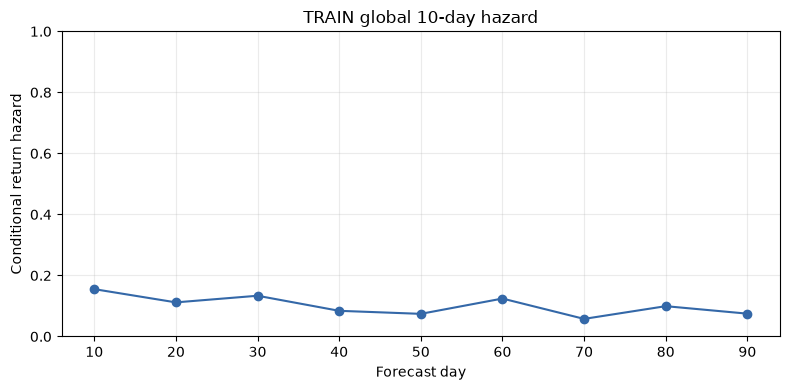

In [4]:
global_model = pc.fit_global_hazard(train_pp)
global_counts = pd.DataFrame({
    "interval_index": np.arange(1, 10),
    "interval": [f"({10*i-10}, {10*i}]" for i in range(1, 10)],
    "at_risk": global_model["at_risk"],
    "events": global_model["events"],
    "hazard": global_model["hazards"],
})
display(global_counts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, 10) * 10, global_model["hazards"], marker="o", color="#3468a8")
ax.set(xlabel="Forecast day", ylabel="Conditional return hazard", title="TRAIN global 10-day hazard")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "global_hazard.png", dpi=150)
plt.show()

## 6. Segment-aware hazard baseline

The segment baseline uses `Hist_Cluster_id` / `Hist_Segment` already assigned by the temporal framework, not the full-year Notebook 04 labels. It estimates segment event hazards and shrinks them toward the global hazard with `alpha=20`. For intervals with fewer than 20 customers at risk in a segment, the global hazard is used directly.

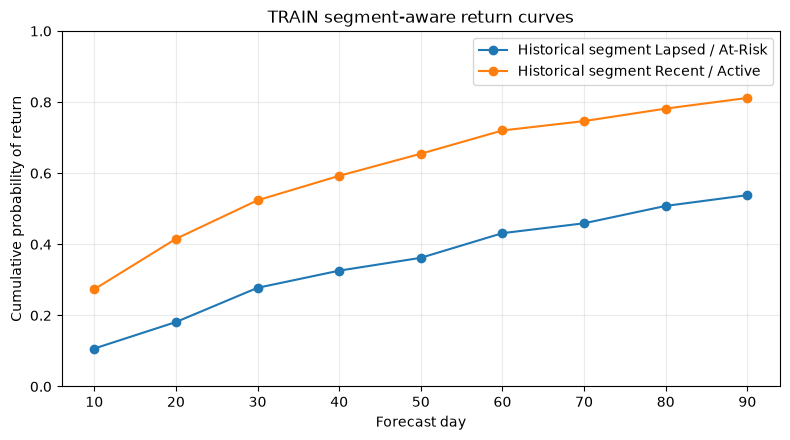

In [5]:
segment_model = pc.fit_segment_hazard(train_pp, global_model, alpha=20, min_at_risk=20)
segment_curves = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
for segment, hazards in sorted(segment_model["hazards_by_segment"].items()):
    curve = pc.hazards_to_cumulative_probabilities(hazards).iloc[0]
    segment_curves[segment] = curve
    ax.plot(
        np.arange(1, 10) * 10,
        [curve[f"purchase_{day}d"] for day in range(10, 91, 10)],
        marker="o", label=f"Historical segment {segment}",
    )
ax.set(xlabel="Forecast day", ylabel="Cumulative probability of return",
       title="TRAIN segment-aware return curves")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "segment_return_curves.png", dpi=150)
plt.show()

## 7. Personalized Logistic Regression hazard model

A pooled scikit-learn pipeline models the interval-specific conditional event indicator. Numeric predictors are Recency, Frequency, gross monetary value, AOV, observed tenure, purchase/spending rates, median historical gap, and recent order count. Skewed non-negative numeric predictors use `log1p`, train-fitted median imputation (with missingness indicators), and standardization. Historical segment and interval are categorical and one-hot encoded. Customer IDs, raw dates, target fields, and future outcome values are excluded.

The L2 Logistic Regression uses `lbfgs`, `max_iter=2000`, and no class weighting. Candidate `C` values are limited to 0.1, 1, and 10.

## 8. Validation-based model selection

The three candidate regularization values are evaluated on the VALIDATION cohort only. The selected value minimizes mean Brier score across 30, 60, and 90 days, with lower `C` as the deterministic tie-break. The pipeline remains fitted on TRAIN; VALIDATION is not added to fitting, and TEST is not passed into selection.

In [6]:
global_model = pc.fit_global_hazard(train_pp)
segment_model = pc.fit_segment_hazard(train_pp, global_model, alpha=20, min_at_risk=20)
population_median_gap = float(train_features["Median_Gap_days"].dropna().median())

selection = pc.fit_personalized_hazard(
    train_pp, val_features, val_outcomes, c_candidates=pc.REGULARIZATION_CANDIDATES
)
display(selection["selection_metrics"])
selected_C = selection["selected_C"]
print(f"Selected C from VAL only: {selected_C}")

metadata = pc.make_model_metadata(
    training_features=train_features,
    training_person_period=train_pp,
    selected_c=selected_C,
    cutoff_date="2010-03-01",
    split_file="data/processed/temporal/predictive_splits_90d.csv",
    population_median_gap=population_median_gap,
)
model_bundle = {
    "global": global_model,
    "segment": segment_model,
    "personalized_pipeline": selection["pipeline"],
    "metadata": metadata,
}

val_predictions = pc.predict_purchase_clock(model_bundle, val_features)
val_metrics, val_calibration = pc.evaluate_purchase_probabilities(val_predictions, val_outcomes)
val_metrics["split"] = "VAL"
val_calibration["split"] = "VAL"
display(val_metrics)

,C,mean_validation_brier_30_60_90,validation_brier_30d
0,10.0,0.196547,0.173688
1,1.0,0.196746,0.173803
2,0.1,0.197703,0.174237


Selected C from VAL only: 10.0


,model,horizon_days,n_customers,actual_purchase_rate,mean_predicted_probability,brier_score,log_loss,roc_auc,average_precision,calibration_error,split
0,Global,30,2703,0.285239,0.349846,0.208052,0.607313,0.500000,0.285239,0.064607,VAL
1,Global,60,2703,0.414724,0.517295,0.253249,0.699647,0.500000,0.414724,0.102571,VAL
2,Global,90,2703,0.495376,0.621006,0.265762,0.725608,0.500000,0.495376,0.125630,VAL
3,Segment-aware,30,2703,0.285239,0.362853,0.189736,0.566034,0.668774,0.402006,0.077614,VAL
4,Segment-aware,60,2703,0.414724,0.531343,0.224388,0.641701,0.681238,0.556610,0.116619,VAL
5,Segment-aware,90,2703,0.495376,0.632926,0.237603,0.667741,0.676359,0.628868,0.137550,VAL
6,Personalized,30,2703,0.285239,0.339336,0.173688,0.529621,0.734827,0.572953,0.061487,VAL
7,Personalized,60,2703,0.414724,0.494791,0.202600,0.593790,0.749435,0.713463,0.087356,VAL
8,Personalized,90,2703,0.495376,0.588114,0.213353,0.620567,0.747791,0.765090,0.102483,VAL


## 9. Final test evaluation

After selecting `C`, the same TRAIN-fitted model is evaluated once on the locked TEST cohort. All three methods use precisely those TEST customers, cutoff, and outcomes. Actual 30/60/90-day labels are built from the order-level data by the existing target function and independently checked against the authorized 90-day split's 90-day target.

In [7]:
# TEST outcomes are first constructed here, after the regularization value is selected.
test_features = role_frames["TEST"]
test_outcomes = tf.compute_future_targets(
    orders, test_features, expected_cutoffs["TEST"], dataset_end, horizons=[30, 60, 90]
)
test_outcomes[pc.CENSOR_FLAG_COL] = (test_outcomes[pc.EVENT_FLAG_COL] == 0).astype(int)
# Reconcile the target function with the authorized TEST target only after selection is final.
test_split_targets = pd.read_csv(
    split_path, usecols=["Customer ID", "split_role", "Purchased_90d"]
)
test_split_targets = test_split_targets.loc[test_split_targets["split_role"].eq("TEST")]
test_check = test_split_targets.merge(
    test_outcomes[["Customer ID", "Purchased_90d"]], on="Customer ID",
    suffixes=("_split", "_orders"), validate="one_to_one",
)
assert len(test_check) == len(test_features)
assert (test_check["Purchased_90d_split"] == test_check["Purchased_90d_orders"]).all()

test_predictions = pc.predict_purchase_clock(model_bundle, test_features)
test_metrics, test_calibration = pc.evaluate_purchase_probabilities(test_predictions, test_outcomes)
test_metrics["split"] = "TEST"
test_calibration["split"] = "TEST"

metric_table = test_metrics[[
    "model", "horizon_days", "n_customers", "actual_purchase_rate",
    "mean_predicted_probability", "brier_score", "log_loss",
    "roc_auc", "average_precision", "calibration_error",
]]
display(metric_table)
assert test_metrics["n_customers"].eq(len(test_features)).all()
assert test_predictions["Customer ID"].nunique() == len(test_features)

,model,horizon_days,n_customers,actual_purchase_rate,mean_predicted_probability,brier_score,log_loss,roc_auc,average_precision,calibration_error
0,Global,30,3373,0.279277,0.349846,0.206261,0.603618,0.500000,0.279277,0.070569
1,Global,60,3373,0.471390,0.517295,0.251289,0.695726,0.500000,0.471390,0.054214
2,Global,90,3373,0.573377,0.621006,0.246884,0.687090,0.500000,0.573377,0.055599
3,Segment-aware,30,3373,0.279277,0.371393,0.192072,0.570823,0.661381,0.383911,0.092116
4,Segment-aware,60,3373,0.471390,0.541361,0.228493,0.649786,0.657208,0.583917,0.069971
5,Segment-aware,90,3373,0.573377,0.642411,0.225635,0.641928,0.654656,0.675248,0.069034
6,Personalized,30,3373,0.279277,0.331483,0.178534,0.540297,0.720882,0.537588,0.062646
7,Personalized,60,3373,0.471390,0.477889,0.214200,0.622649,0.721767,0.716292,0.061482
8,Personalized,90,3373,0.573377,0.565369,0.215308,0.628226,0.719368,0.784723,0.071720


## 10. Calibration analysis

Reliability bins are formed at the customer level, not from interval rows. The weighted absolute difference between average predicted probability and observed purchase rate is reported as calibration error. ROC-AUC and average precision are reported separately because ranking performance does not establish calibration.

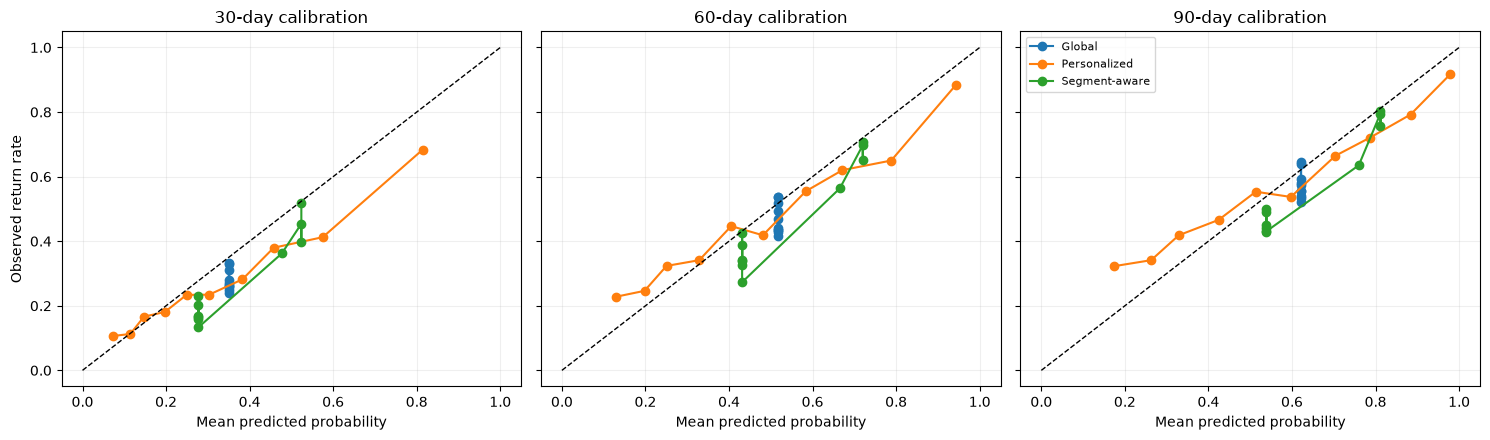

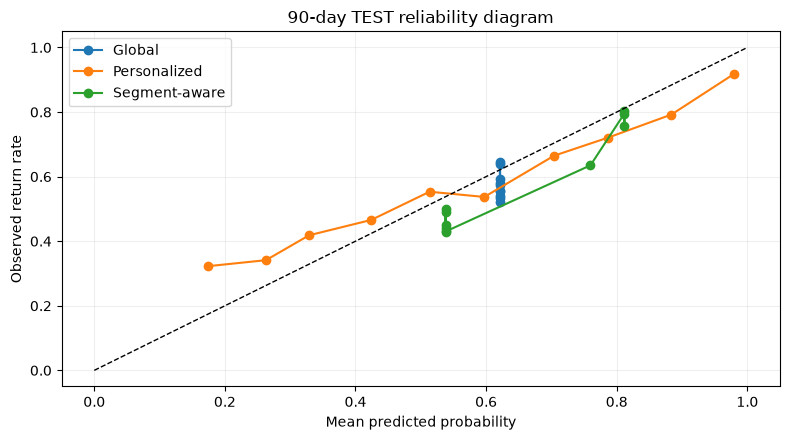

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, horizon in zip(axes, (30, 60, 90)):
    subset = test_calibration[test_calibration["horizon_days"].eq(horizon)]
    for model_name, curve in subset.groupby("model"):
        ax.plot(curve["mean_predicted"], curve["observed_rate"], marker="o", label=model_name)
    ax.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1)
    ax.set(title=f"{horizon}-day calibration", xlabel="Mean predicted probability")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Observed return rate")
axes[-1].legend(loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_calibration.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for model_name, curve in test_calibration[test_calibration["horizon_days"].eq(90)].groupby("model"):
    ax.plot(curve["mean_predicted"], curve["observed_rate"], marker="o", label=model_name)
ax.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1)
ax.set(xlabel="Mean predicted probability", ylabel="Observed return rate",
       title="90-day TEST reliability diagram")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_calibration_90d.png", dpi=150)
plt.show()

## 11. Individual customer purchase clocks

The inference interface receives only cutoff-time customer features. It returns the three cumulative probability curves, survival probabilities, an in-horizon median interval if the 50% threshold is reached, historical segment, delay ratio, and history sufficiency. It does not return future target fields. The examples below are sampled from the real TEST cohort.

,Customer ID,cutoff_date,Hist_Segment,Recency,Frequency,global_P30,global_P60,global_P90,segment_P30,segment_P60,segment_P90,personalized_P30,personalized_P60,personalized_P90,personalized_median_return_interval,delay_ratio,history_sufficiency
2,12355,2010-09-10,Lapsed / At-Risk,111,1,0.349846,0.517295,0.621006,0.277589,0.431324,0.538225,0.159114,0.269643,0.352939,Median return time not reached within the mode...,5.297100,Exactly one purchase
1,12349,2010-09-10,Lapsed / At-Risk,114,2,0.349846,0.517295,0.621006,0.277589,0.431324,0.538225,0.218467,0.360631,0.462101,Median return time not reached within the mode...,5.579783,Two to four purchases
0,12346,2010-09-10,Recent / Active,73,11,0.349846,0.517295,0.621006,0.523814,0.720161,0.811703,0.305589,0.484451,0.601303,"(60, 70] days",7.731598,Five or more purchases


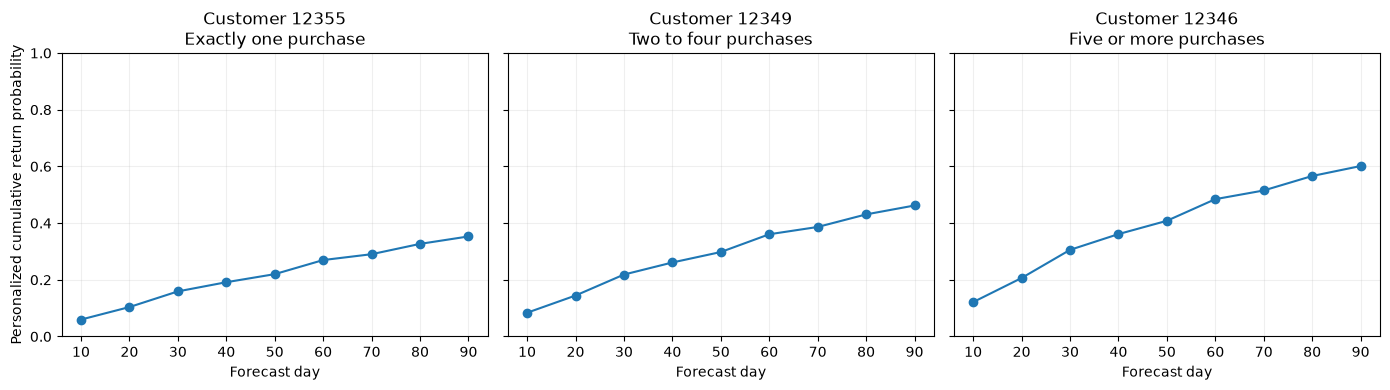

In [9]:
example_groups = ["Exactly one purchase", "Two to four purchases", "Five or more purchases"]
examples = []
for group in example_groups:
    candidate = test_predictions.loc[test_predictions["history_group"].eq(group)]
    if candidate.empty:
        raise ValueError(f"The TEST cohort has no customers in required example group: {group}")
    examples.append(candidate.iloc[0])
example_table = pd.DataFrame(examples)[[
    "Customer ID", "cutoff_date", "Hist_Segment", "Recency", "Frequency",
    "global_P30", "global_P60", "global_P90",
    "segment_P30", "segment_P60", "segment_P90",
    "personalized_P30", "personalized_P60", "personalized_P90",
    "personalized_median_return_interval", "delay_ratio", "history_sufficiency",
]]
display(example_table)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, row in zip(axes, examples):
    days = np.arange(10, 91, 10)
    ax.plot(days, [row[f"personalized_purchase_{day}d"] for day in days], marker="o")
    ax.set(title=f"Customer {row['Customer ID']}\n{row['history_group']}",
           xlabel="Forecast day", ylim=(0, 1))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Personalized cumulative return probability")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "three_test_customer_clocks.png", dpi=150)
plt.show()

## 12. Sparse-history evaluation

The personalized model is pooled across customers; it is not fitted separately for individual customers. TEST performance is summarized for exactly one prior purchase, two to four purchases, and five or more purchases. The one-purchase group has no personal purchase-gap estimate and is handled with train-fitted imputation plus a missingness indicator.

,history_group,horizon_days,n_customers,actual_purchase_rate,mean_predicted_probability,brier_score,roc_auc
0,Exactly one purchase,30,1281,0.137393,0.155118,0.119242,0.582307
1,Exactly one purchase,60,1281,0.281030,0.259338,0.202255,0.581774
2,Exactly one purchase,90,1281,0.378610,0.336149,0.240464,0.568365
3,Five or more purchases,30,726,0.545455,0.640276,0.243338,0.662060
4,Five or more purchases,60,726,0.768595,0.809042,0.173917,0.684332
5,Five or more purchases,90,726,0.855372,0.880436,0.122821,0.678813
6,Two to four purchases,30,1366,0.270864,0.332757,0.199695,0.602955
7,Two to four purchases,60,1366,0.491947,0.506840,0.246812,0.608865
8,Two to four purchases,90,1366,0.606149,0.612873,0.240871,0.601874


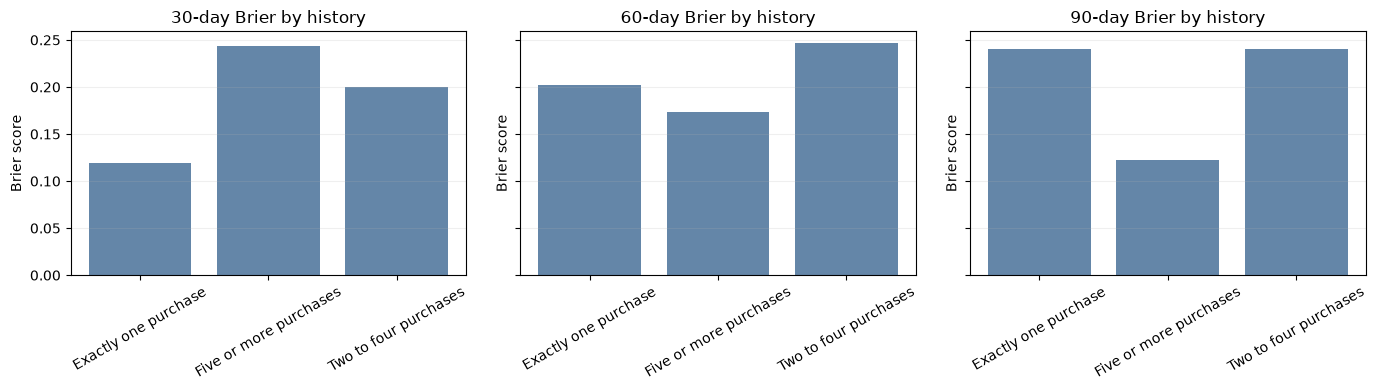

In [10]:
history_metrics = pc.performance_by_history_group(test_predictions, test_outcomes)
display(history_metrics)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, horizon in zip(axes, (30, 60, 90)):
    subset = history_metrics[history_metrics["horizon_days"].eq(horizon)]
    ax.bar(subset["history_group"], subset["brier_score"], color="#6486a8")
    ax.set(title=f"{horizon}-day Brier by history", ylabel="Brier score")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "performance_by_history.png", dpi=150)
plt.show()

## 13. Personalized delay-ratio analysis

The delay ratio is `Recency / RegularizedExpectedGap`, where `RegularizedExpectedGap = (n_gaps × MedianGap + 3 × TRAIN population median gap) / (n_gaps + 3)`. It is a purchasing-delay heuristic only, **not** a calibrated churn probability or a validated risk category. No arbitrary high-risk labels are assigned.

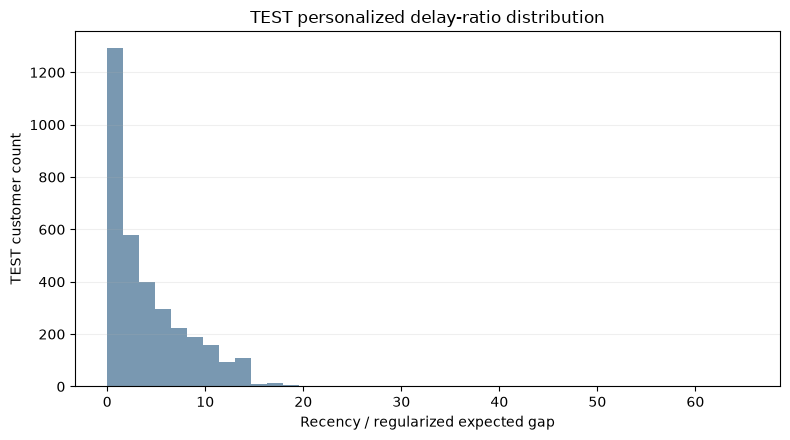

Interpretation: a high ratio indicates unusually long delay relative to the regularized historical gap; it is not a churn probability.


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
finite_delay = test_predictions["delay_ratio"].replace([np.inf, -np.inf], np.nan).dropna()
ax.hist(finite_delay, bins=40, color="#6286a4", alpha=0.85)
ax.set(xlabel="Recency / regularized expected gap", ylabel="TEST customer count",
       title="TEST personalized delay-ratio distribution")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "delay_ratio_distribution.png", dpi=150)
plt.show()
print("Interpretation: a high ratio indicates unusually long delay relative to the regularized historical gap; it is not a churn probability.")

## 14. Model limitations

- This is a one-year UK retail dataset with sparse customer histories; forecasts are historical backtests at fixed 2010 cutoffs.
- Customers with one purchase have no observed individual interpurchase gap; pooled imputation and indicators support predictions but do not create individual evidence.
- Expanding customers into intervals induces within-customer dependence. This notebook evaluates metrics on one row per customer and does not use naive interval-row standard errors.
- The segment and personalized models are observational and do not establish that an intervention will cause a return.
- Return within 30/60/90 days is not equivalent to long-term retention or permanent churn.
- No claim is made that this model generalizes to other businesses or datasets.
- Revenue, behavioral deterioration, and intervention-effect models are intentionally out of scope for Notebook 06.

## 15. Artifact export and automated verification

The prediction export is kept separate from evaluation files containing observed future outcomes. Saved model objects and JSON metadata allow inference without re-running this notebook. The fitted preprocessing pipeline is part of the model bundle.

In [12]:
# Save the selected TRAIN-fitted models for notebook-free inference.
model_path = pc.save_purchase_clock_artifacts(model_bundle, MODEL_DIR)

# Persist validation and test metrics, and calibration bins, with explicit split labels.
selection_metrics_path = OUTPUT_DIR / "validation_selection_metrics.csv"
val_metrics_path = OUTPUT_DIR / "validation_metrics.csv"
test_metrics_path = OUTPUT_DIR / "test_metrics.csv"
calibration_path = OUTPUT_DIR / "calibration_results.csv"
history_path = OUTPUT_DIR / "performance_by_history_group.csv"
predictions_path = OUTPUT_DIR / "test_predictions.csv"
evaluation_path = OUTPUT_DIR / "test_evaluation.csv"

selection["selection_metrics"].to_csv(selection_metrics_path, index=False)
val_metrics.to_csv(val_metrics_path, index=False)
test_metrics.to_csv(test_metrics_path, index=False)
pd.concat([val_calibration, test_calibration], ignore_index=True).to_csv(calibration_path, index=False)
history_metrics.to_csv(history_path, index=False)

# This file intentionally contains no future purchase dates or target labels.
assert not set(test_predictions.columns).intersection(pc.TARGET_COLUMNS)
test_predictions.to_csv(predictions_path, index=False)

# Actual outcomes are joined only in a separate evaluation file.
actual_labels = pc.derive_horizon_outcomes(test_outcomes)
evaluation = test_predictions.merge(
    test_outcomes[["Customer ID", "NextPurchaseDate", "TimeToNext_days", "Event_flag"]],
    on="Customer ID", validate="one_to_one",
).merge(actual_labels, on="Customer ID", validate="one_to_one")
evaluation.to_csv(evaluation_path, index=False)

# Re-load the saved bundle and assert deterministic inference.
reloaded = pc.load_purchase_clock_artifacts(MODEL_DIR)
reloaded_predictions = pc.predict_purchase_clock(reloaded, test_features)
probability_cols = [c for c in test_predictions if c.endswith(("_P30", "_P60", "_P90"))]
np.testing.assert_allclose(
    test_predictions[probability_cols].to_numpy(),
    reloaded_predictions[probability_cols].to_numpy(),
    rtol=0, atol=1e-12,
)
assert len(test_predictions) == len(test_features)
print(f"Saved model bundle: {model_path}")
print(f"Saved TEST predictions without targets: {predictions_path} ({len(test_predictions):,} rows)")
print(f"Saved TEST evaluation with observed outcomes: {evaluation_path} ({len(evaluation):,} rows)")
print("Reload check: identical probability predictions.")

smoke = pc.run_purchase_clock_tests()
assert all(value == "PASS" for value in smoke.values()), smoke
print(smoke)

Saved model bundle: /home/runner/workspace/OELP_project/models/purchase_clock/purchase_clock.joblib
Saved TEST predictions without targets: /home/runner/workspace/OELP_project/data/processed/purchase_clock/test_predictions.csv (3,373 rows)
Saved TEST evaluation with observed outcomes: /home/runner/workspace/OELP_project/data/processed/purchase_clock/test_evaluation.csv (3,373 rows)
Reload check: identical probability predictions.
{'hazards_in_unit_interval': 'PASS', 'survival_nonincreasing': 'PASS', 'purchase_probability_nondecreasing': 'PASS', 'p30_le_p60_le_p90': 'PASS'}


In [13]:
# Summarize the selected configuration and the observed TEST findings from computed tables.
print(f"Validation-selected C: {selected_C:g}")
for horizon in (30, 60, 90):
    rows = test_metrics.loc[test_metrics["horizon_days"].eq(horizon)].sort_values("brier_score")
    winner = rows.iloc[0]
    personal = rows.loc[rows["model"].eq("Personalized")].iloc[0]
    global_row = rows.loc[rows["model"].eq("Global")].iloc[0]
    segment_row = rows.loc[rows["model"].eq("Segment-aware")].iloc[0]
    print(
        f"{horizon}d TEST: {winner['model']} has the lowest Brier score "
        f"({winner['brier_score']:.4f}); personalized={personal['brier_score']:.4f}, "
        f"segment-aware={segment_row['brier_score']:.4f}, global={global_row['brier_score']:.4f}. "
        f"Personalized mean prediction={personal['mean_predicted_probability']:.3f}; "
        f"observed rate={personal['actual_purchase_rate']:.3f}; "
        f"AUC={personal['roc_auc']:.3f}, AP={personal['average_precision']:.3f}."
    )
print("The personalized model improves Brier score over both baselines at all three horizons in this held-out cohort.")
print("Sparse-history results vary by group and horizon; use the displayed subgroup table rather than treating one summary score as universal.")
print("All findings are historical associations for this Year 1 dataset; they do not establish intervention effects or cross-business generalization.")

Validation-selected C: 10
30d TEST: Personalized has the lowest Brier score (0.1785); personalized=0.1785, segment-aware=0.1921, global=0.2063. Personalized mean prediction=0.331; observed rate=0.279; AUC=0.721, AP=0.538.
60d TEST: Personalized has the lowest Brier score (0.2142); personalized=0.2142, segment-aware=0.2285, global=0.2513. Personalized mean prediction=0.478; observed rate=0.471; AUC=0.722, AP=0.716.
90d TEST: Personalized has the lowest Brier score (0.2153); personalized=0.2153, segment-aware=0.2256, global=0.2469. Personalized mean prediction=0.565; observed rate=0.573; AUC=0.719, AP=0.785.
The personalized model improves Brier score over both baselines at all three horizons in this held-out cohort.
Sparse-history results vary by group and horizon; use the displayed subgroup table rather than treating one summary score as universal.
All findings are historical associations for this Year 1 dataset; they do not establish intervention effects or cross-business generalizati

## 16. Conclusions and readiness for the next project stage

The model comparison above reports actual validation-selected and out-of-time TEST results. The best model is not assumed in advance: if either baseline scores better, that is the result to report. Notebook 07 and the later Streamlit application should consume `models/purchase_clock/purchase_clock.joblib` through `load_purchase_clock_artifacts()` and query it through `predict_purchase_clock()`. `test_predictions.csv` contains model output only; `test_evaluation.csv` is reserved for retrospective evaluation and includes actual future labels. The model does not require notebook execution for ordinary inference.